In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from alpha import Alpha
from kernel.reversal import Reversal

### Задача 1

In [2]:
a = Alpha(Reversal(5))
v = pd.DataFrame([[3.0,-1.0,4.0,1.0,-5.0,9.0,2.0]])
v_neut = a._netralization(v)
print(v_neut.sum(axis=1).iloc[0])
v_neut

-1.3322676295501878e-15


,0,1,2,3,4,5,6
0,1.142857,-2.857143,2.142857,-0.857143,-6.857143,7.142857,0.142857


### Задача 2

In [3]:
v_norm = a._normalization(v_neut)
print(v_norm.abs().sum(axis=1).iloc[0])
v_norm

1.0


,0,1,2,3,4,5,6
0,0.054054,-0.135135,0.101351,-0.040541,-0.324324,0.337838,0.006757


### Задача 3

In [4]:
pos = a()
print(pos.iloc[[10,500,1000]].sum(axis=1))
print(pos.iloc[[10,500,1000]].abs().sum(axis=1))
pos.iloc[[10,500,1000],:6]

Date
2016-01-19    8.096280e-17
2017-12-27    6.505213e-19
2019-12-23   -1.387779e-17
dtype: float64


Date
2016-01-19    1.0
2017-12-27    1.0
2019-12-23    1.0
dtype: float64


,A,AACG,AAMI,AAOI,AAPL,AAT
Date,,,,,,
2016-01-19,-0.000513,-0.002394,0.001685,0.001511,-0.000521,-0.000520
2017-12-27,0.000462,-0.000036,0.000395,0.002465,0.000891,0.000354
2019-12-23,0.000106,0.000531,0.000148,0.000168,-0.000029,0.000409


### Задача 4

In [5]:
pnl = a.pnl()
pnl.head(10)

Date
2016-01-04    0.000000
2016-01-05    0.000000
2016-01-06    0.000000
2016-01-07    0.000000
2016-01-08    0.000000
2016-01-11    0.000000
2016-01-12   -0.000726
2016-01-13   -0.012986
2016-01-14    0.010025
2016-01-15   -0.004889
dtype: float64

### Задача 5

In [6]:
to = a.turnover()
to.head(10)

Date
2016-01-04    0.000000
2016-01-05    0.000000
2016-01-06    0.000000
2016-01-07    0.000000
2016-01-08    0.000000
2016-01-11    1.000000
2016-01-12    0.424331
2016-01-13    0.428243
2016-01-14    0.613718
2016-01-15    0.533503
dtype: float64

### Задача 6

In [7]:
a.sharpe_ratio()

2.273188187688393

### Задача 7

<Axes: xlabel='Дата', ylabel='Накопленная доходность'>

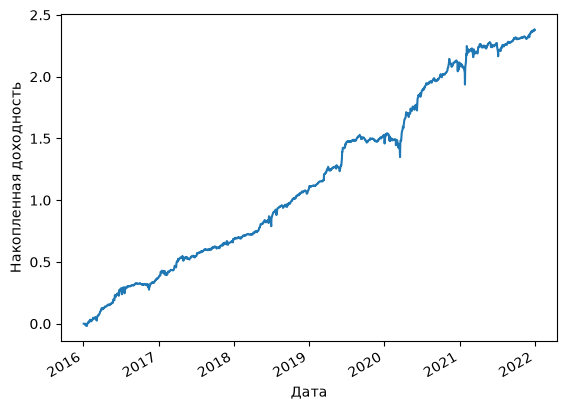

In [8]:
a.cumulative().plot(xlabel="Дата",ylabel="Накопленная доходность")

### Задача 8

In [9]:
a.max_drawdown()

0.2076456518685721

### Задача 9

,sharpe,turnover,return,drawdown
2016,2.825972,0.637155,0.369579,0.053869
2017,2.818930,0.650187,0.316926,0.036488
2018,3.041565,0.649929,0.399653,0.081430
2019,3.451725,0.643701,0.440695,0.062777
2020,2.301824,0.653366,0.564473,0.191954
2021,1.178251,0.649417,0.288212,0.169785


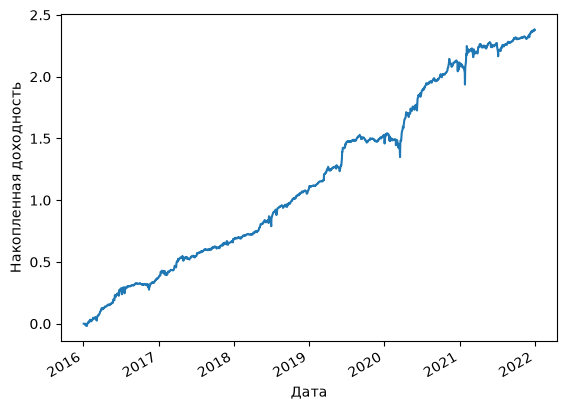

In [10]:
a.alpha_stats()

### Задача 10

In [11]:
a._truncate(v,3.0)

,0,1,2,3,4,5,6
0,3.0,-1.0,3.0,1.0,-3.0,3.0,2.0


### Задача 11

In [12]:
a._rank(v)

,0,1,2,3,4,5,6
0,0.666667,0.166667,0.833333,0.333333,0.0,1.0,0.5


### Задача 12

MGF     0.005489
MIN     0.005961
WIW     0.006136
NRK     0.006392
FMY     0.006414
          ...   
MPU     0.132199
GPUS    0.132765
AACG    0.257092
NBY     0.258432
GBR     0.267872
Length: 1294, dtype: float64

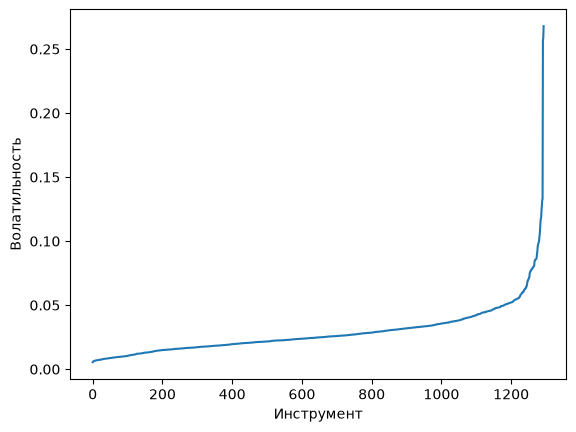

In [13]:
a.volatility()

### Задача 13

In [14]:
a._cut_outliers(v,2)

,0,1,2,3,4,5,6
0,3.0,0.0,0.0,1.0,0.0,0.0,2.0


### Задача 14

In [15]:
a._cut_middle(v,3)

,0,1,2,3,4,5,6
0,0.0,-1.0,4.0,0.0,-5.0,9.0,0.0


### Задача 15

In [16]:
a2 = Alpha(Reversal(10))
a.correlation(a2)

0.8692389818868292

### Задача 16

In [17]:
for n in [1,3,5,10]:
    d = a._decay(pos,n) if n > 1 else pos
    print(n,d.diff().abs().sum(axis=1).mean())

1 0.6472928695618491
3 0.4412661007146932


5 0.3798235334841203


10 0.2719381751930169
